# EDA : Exploratory Data Analysis is the process where we explore data statistically so that we get to know what all are the information inside dataset

1) In this project we will explore data of patients in a hospital and create analytical dashboard to show required information on website
2) to start this project create database file and hospital_data.db file should exist in current project folder

# hospital_data.db is the file where database ,dataset will be stored

# create_hospital_db.sql is the file by using which we will create a database inside hospital _data.db

go to cmd and type pip install sqlite3

In [1]:
import sqlite3 as sql

In [2]:
conn = sql.connect('hospital_data.db') # connecting database file for storage
cursor = conn.cursor() # creating cursor to execute sql querries by using python
with open('create_hospital_db.sql','r',encoding='utf-8-sig') as file:
    queries = file.read() # reading sql querries to create database inside hospital_data.db

In [82]:
for i in queries.split(';'):
    if not(i.startswith('--')):
        cursor.executescript(i) # executing sql and storing data in hospital_data.db
        conn.commit() # making permanent changes

In [3]:
# queries

In [4]:
import pandas as pd
pd.read_sql('select * from payers;',conn)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323
1,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244,1-800-633-4227
2,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323
3,d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018,1-844-330-7799
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007,1-800-262-2583
5,5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare,9800 Healthcare Lane,Minnetonka,MN,55436,1-888-545-5205
6,4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna,151 Farmington Ave,Hartford,CT,06156,1-800-872-3862
7,047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health,900 Cottage Grove Rd,Bloomfield,CT,06002,1-800-997-1654
8,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204,1-800-331-1476
9,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,NaN,NaN,NaN,NaN,NaN


In [5]:
import pandas as pd
pd.read_sql('select * from sqlite_master;',conn)

,type,name,tbl_name,rootpage,sql
0,table,payers,payers,2,CREATE TABLE payers (\n Id CHAR(36) PRIMARY...
1,index,sqlite_autoindex_payers_1,payers,3,NaN
2,table,patients,patients,4,CREATE TABLE patients (\n Id CHAR(36) PRIMA...
3,index,sqlite_autoindex_patients_1,patients,5,NaN
4,table,procedures,procedures,72,CREATE TABLE procedures (\n START TIMESTAMP...
5,table,encounters,encounters,2220,CREATE TABLE encounters (\n Id CHAR(36) PRIMA...
6,index,sqlite_autoindex_encounters_1,encounters,2221,NaN


In [6]:
pay=pd.read_sql('select * from payers;',conn)
pat=pd.read_sql('select * from patients;',conn)
enc=pd.read_sql('select * from encounters;',conn)

In [7]:
dfs=[('payers',pay),('patients',pat),('Encounter',enc)]

In [8]:
for N,i in dfs:
    print(N,'=>',i.columns) # please refer data dictionary for details description of column name

payers => Index(['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE'], dtype='str')
patients => Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX',
       'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE',
       'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON'],
      dtype='str')
Encounter => Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='str')


In [9]:
for N,df in dfs:
    print('Statical Info for Numeric Data')
    print(N)
    print(N,df.describe().T)
    print('Statistical Info for Categorical Data')
    print(N)
    print(N,df.describe(include='str').T)

Statical Info for Numeric Data
payers
payers                     count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CITY                    9      7                             Baltimore    3
STATE_HEADQUARTERED     9      6                                    MD    3
ZIP                     9      7                                 21244    3
PHONE                   9      8                        1-877-267-2323    2
Statistical Info for Categorical Data
payers
payers                     count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security B

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

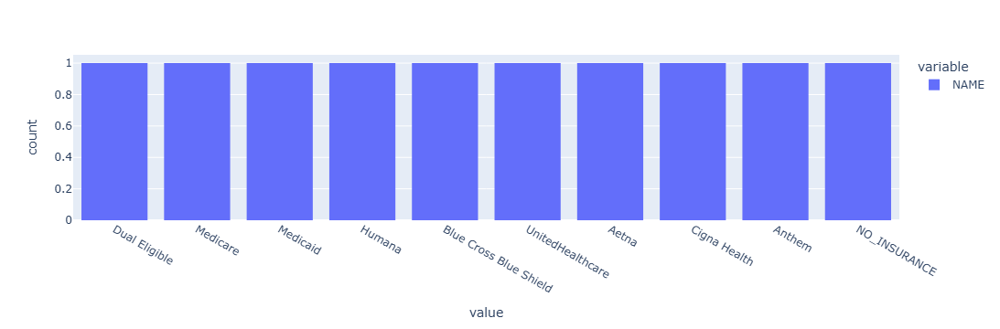

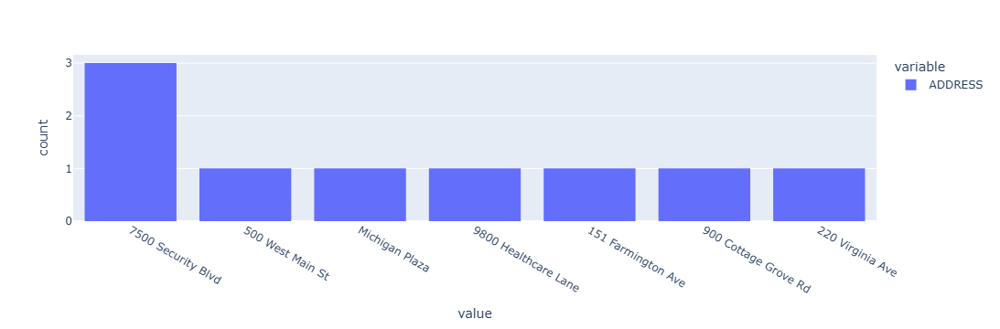

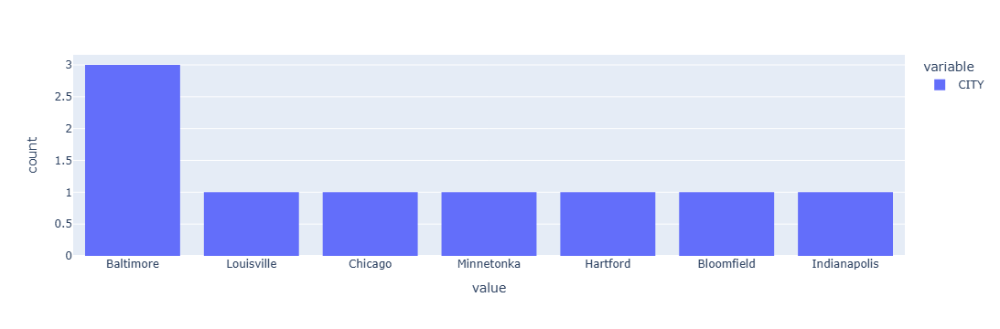

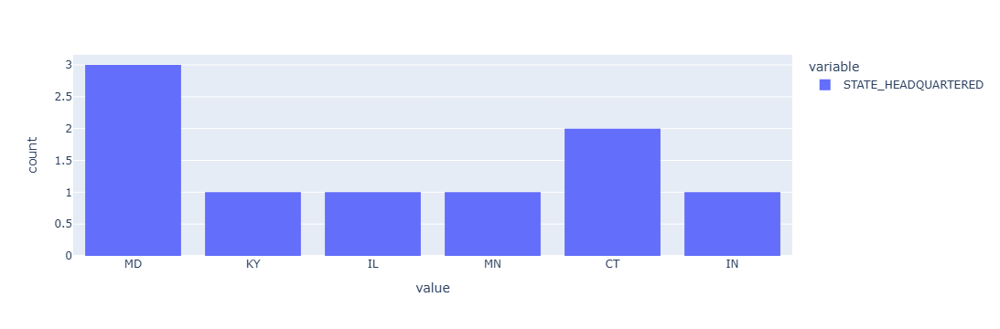

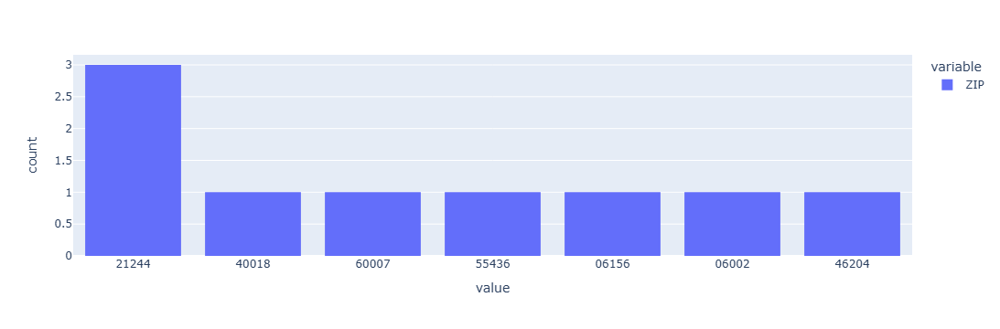

...

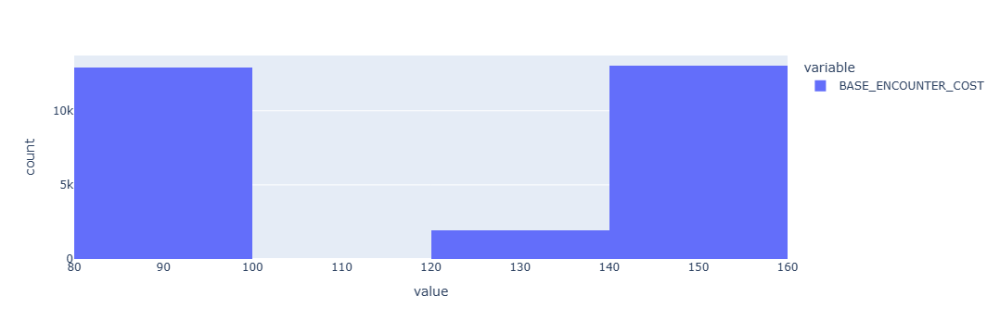

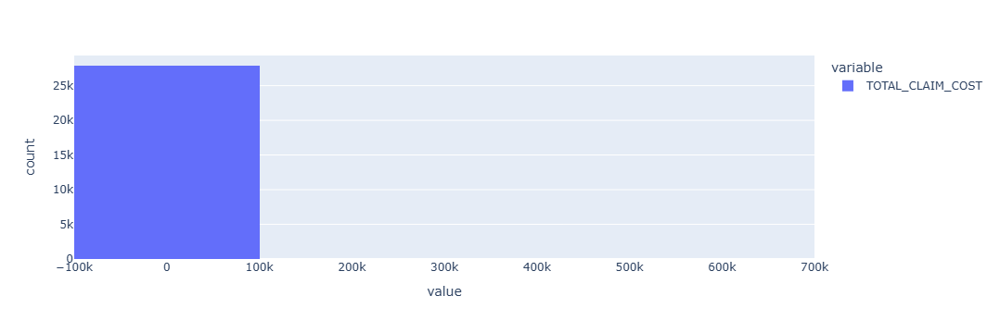

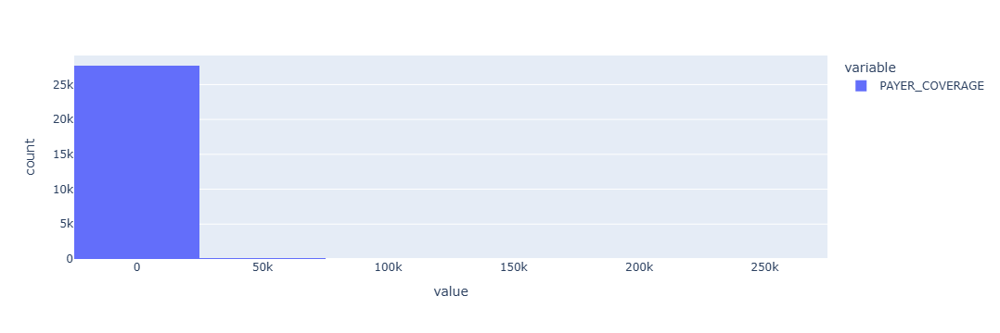

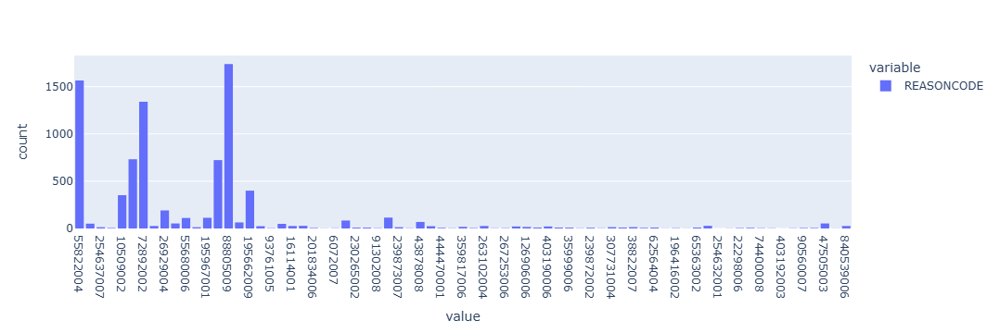

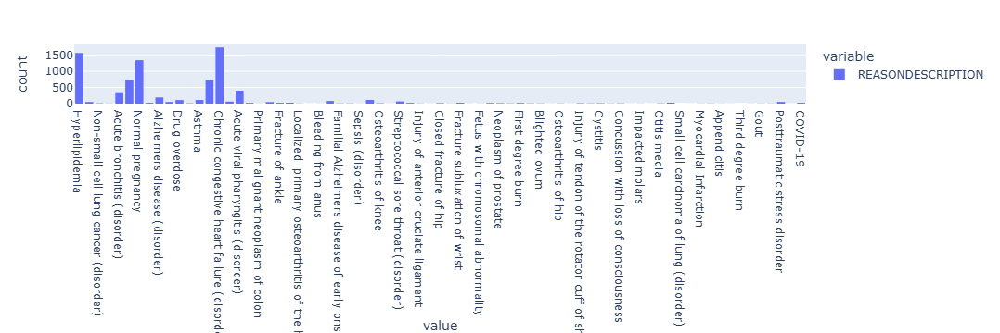

In [11]:
for N,df in dfs:
    for col in df.columns:
        if df[col].dtypes!='object' and 'id' not in col.lower():
            fig=px.histogram(df[col],nbins=5)
            fig.show()
        elif df[col].dtypes=='object' and 'id' not in col.lower():
            fig=px.histogram(df[col],text_auto=True)
            fig.show()

In [12]:
dfs[0][1].dtypes

Id                     str
NAME                   str
ADDRESS                str
CITY                   str
STATE_HEADQUARTERED    str
ZIP                    str
PHONE                  str
dtype: object

In [13]:
dfs[1][1].dtypes

Id                str
BIRTHDATE         str
DEATHDATE      object
PREFIX            str
FIRST             str
LAST              str
SUFFIX         object
MAIDEN            str
MARITAL           str
RACE              str
ETHNICITY         str
GENDER            str
BIRTHPLACE        str
ADDRESS           str
CITY              str
STATE             str
COUNTY            str
ZIP               str
LAT           float64
LON           float64
dtype: object

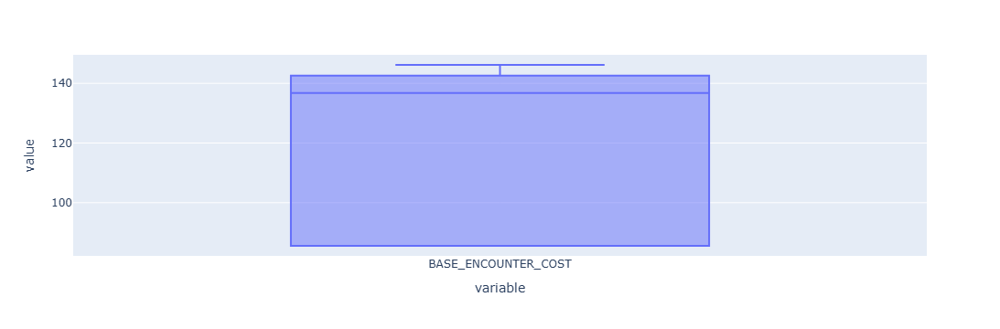

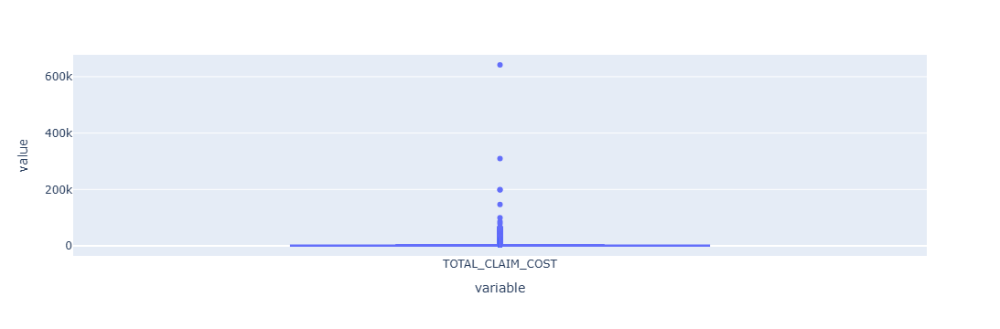

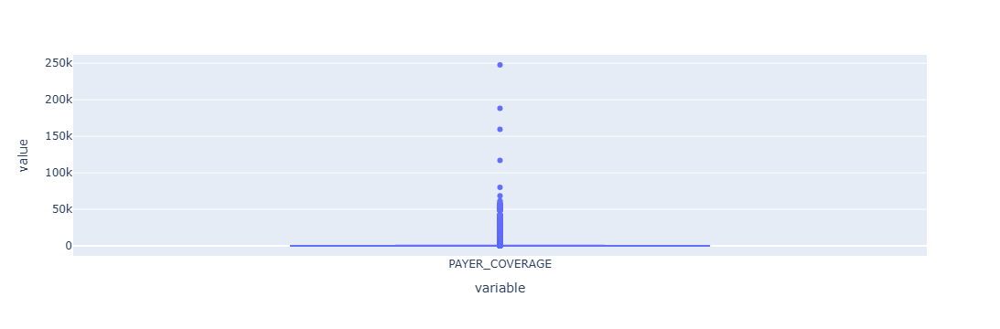

In [14]:
for i in dfs[2][1].columns:
    if dfs[2][1][i].dtypes!='str':
        fig=px.box(dfs[2][1][i])
        fig.show()

In [15]:
paydf=dfs[2][1][['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE']]

In [16]:
paydf=pd.melt(paydf,value_vars=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE']).rename(columns ={'variable':'cost_category','value':'cost'})

In [17]:
paydf=paydf.groupby('cost_category').agg({'cost':'sum'}).reset_index().sort_values('cost',ascending=False)

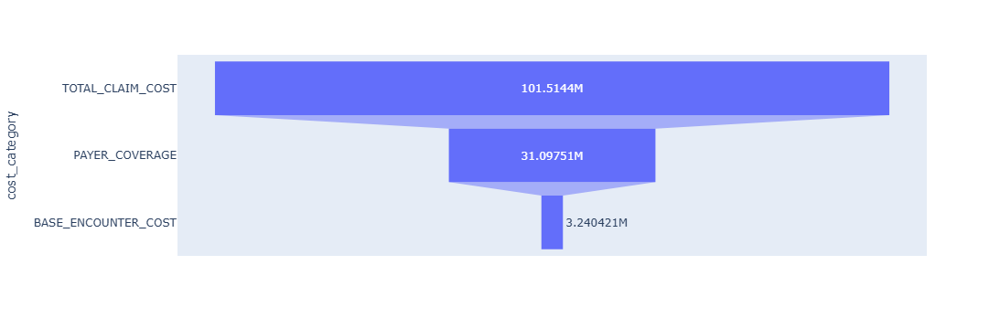

In [18]:
px.funnel(paydf,x='cost',y='cost_category')

In [19]:
dfs[2][1].describe().T

,count,mean,std,min,25%,50%,75%,max
BASE_ENCOUNTER_COST,27891.0,116.181614,28.410082,85.55,85.55,136.80,142.58,146.18
TOTAL_CLAIM_COST,27891.0,3639.682174,9205.595748,0.00,142.58,278.58,1412.53,641882.70
PAYER_COVERAGE,27891.0,1114.965652,4768.615576,0.00,0.00,28.44,155.77,247751.42


In [20]:
dfs[0][1].describe(include='str').T

,count,unique,top,freq
Id,10,10,b3221cfc-24fb-339e-823d-bc4136cbc4ed,1
NAME,10,10,Dual Eligible,1
ADDRESS,9,7,7500 Security Blvd,3
CITY,9,7,Baltimore,3
STATE_HEADQUARTERED,9,6,MD,3
ZIP,9,7,21244,3
PHONE,9,8,1-877-267-2323,2


In [21]:
dfs[1][1].describe(include='str').T

,count,unique,top,freq
Id,973,973,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1
BIRTHDATE,973,879,1929-01-28,4
PREFIX,973,3,Mr.,494
FIRST,973,841,Armando772,3
LAST,973,498,Heaney114,6
MAIDEN,973,280,,588
MARITAL,973,3,M,783
RACE,973,6,white,679
ETHNICITY,973,2,nonhispanic,782
GENDER,973,2,M,494


In [22]:
dfs[2][1].describe(include='str').T

,count,unique,top,freq
Id,27891,27891,32c84703-2481-49cd-d571-3899d5820253,1
START,27891,27541,2016-12-08 10:00:40,3
STOP,27891,27765,2016-12-08 10:15:40,3
PATIENT,27891,974,1712d26d-822d-1e3a-2267-0a9dba31d7c8,1381
ORGANIZATION,27891,1,d78e84ec-30aa-3bba-a33a-f29a3a454662,27891
PAYER,27891,10,7caa7254-5050-3b5e-9eae-bd5ea30e809c,11371
ENCOUNTERCLASS,27891,6,ambulatory,12537
CODE,27891,45,185347001,5261
DESCRIPTION,27891,53,Encounter for problem (procedure),4308
REASONCODE,8350,73,88805009,1738


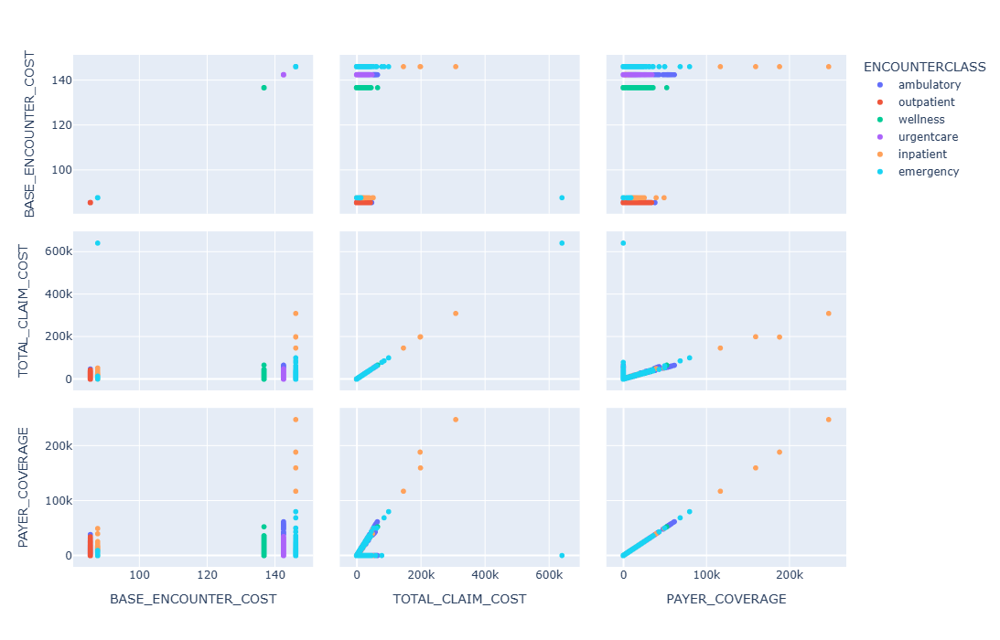

In [23]:
fig=px.scatter_matrix(dfs[2][1],dimensions=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE'],color='ENCOUNTERCLASS')
fig.update_layout(width=1000,height=700)

In [24]:
# total insurance companies
print('Total insurance companies:',len(dfs[0][1]['NAME'].unique())-1)

Total insurance companies: 9


In [25]:
dfs[1][1].head(1)

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,None,Mrs.,Nikita578,Erdman779,None,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,02186,42.290937,-70.975503


In [26]:
bd= pd.to_datetime(dfs[1][1]['BIRTHDATE'])

In [27]:
import datetime as dt

In [28]:
age=(dt.datetime.now().year-bd.dt.year).astype('int8')

In [29]:
print('Average age of a patient:',round(age.mean(),0))

Average age of a patient: 74.0


In [30]:
round((dfs[1][1]['GENDER'].value_counts()/(494+479))*100,0).astype(str).str[:-2]+'%'

GENDER
M    51%
F    49%
Name: count, dtype: str

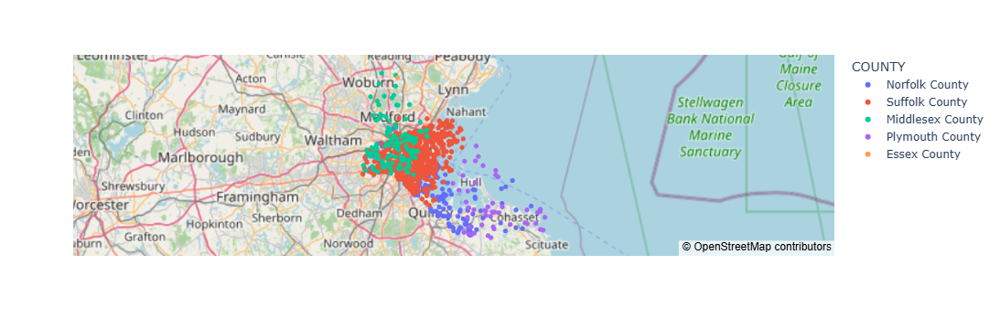

In [31]:
px.scatter_map(dfs[1][1],lat='LAT',lon='LON',hover_name='STATE',color='COUNTY',map_style='open-street-map')

# Dashboard Building

In [32]:
# total patients
dfs[1][1]['Id'].nunique()

973

In [33]:
dfs[2][1]['START']=pd.to_datetime(dfs[2][1]['START'])
dfs[2][1]['STOP']=pd.to_datetime(dfs[2][1]['STOP'])

In [34]:
Time_wise_patients=dfs[2][1].groupby([dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg({'PATIENT':'nunique'})

In [35]:
This_month=Time_wise_patients.iloc[-2,-1]
Last_month=Time_wise_patients.iloc[-3,-1]
Growth= ((This_month/Last_month)-1)*100
print(str(round(Growth))+'%')

-6%


In [36]:
# total encounters
dfs[2][1]

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004,Hyperlipidemia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27886,917bb534-2ed3-e1f5-ac27-74f314d19c63,2022-01-29 11:42:06,2022-01-29 11:57:06,0c122290-8c15-77ac-b418-2fea4e8a8e6a,d78e84ec-30aa-3bba-a33a-f29a3a454662,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,outpatient,185349003,Encounter for check up (procedure),85.55,85.55,24.27,NaN,NaN
27887,07710480-9d6b-9c9b-87c3-c1d54df4069d,2022-01-29 20:12:53,2022-01-29 20:27:53,20a4bc24-6b69-2f5c-dc74-1df390cae25b,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,urgentcare,702927004,Urgent care clinic (procedure),142.58,10588.34,8438.67,NaN,NaN
27888,01b57f06-cebe-a3e4-4423-a796ffb0c35d,2022-01-29 20:35:37,2022-01-29 20:50:37,ff1b3c26-53a6-4590-ce79-a3f7269274ea,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,424619006,Prenatal visit,142.58,11984.29,0.00,72892002,Normal pregnancy
27889,7d435668-0813-eb3b-0f26-cb741fb39561,2022-01-29 20:35:37,2022-01-29 20:50:37,ff1b3c26-53a6-4590-ce79-a3f7269274ea,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,408.80,0.00,NaN,NaN


In [37]:
dfs[2][1]['Id'].nunique()

27891

In [38]:
Time_wise_encounters=dfs[2][1].groupby([dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg({'Id':'nunique'})

In [39]:
This_monthE=Time_wise_encounters.iloc[-2,-1]
Last_monthE=Time_wise_encounters.iloc[-3,-1]
GrowthE= ((This_monthE/Last_monthE)-1)*100
print(str(round(GrowthE))+'%')

-5%


In [40]:
years = [i[0] for i in Time_wise_encounters.index] #extraction of years from index
month = [i[1] for i in Time_wise_encounters.index] # extraction of month from index

In [41]:
Time_wise_encounters['year']=years # creating new column for year
Time_wise_encounters['month']=month  # creating new column for month

In [42]:
Time_wise_encounters.reset_index(drop=True)

,Id,year,month
0,86,2011,1
1,86,2011,2
2,129,2011,3
3,113,2011,4
4,131,2011,5
...,...,...,...
129,225,2021,10
130,267,2021,11
131,231,2021,12
132,219,2022,1


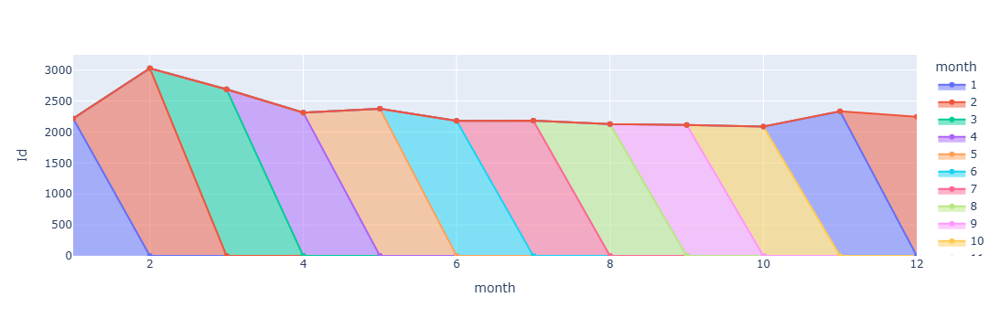

In [43]:
ME = Time_wise_encounters.groupby('month').agg({'Id':'sum'}).reset_index() # dropping index of time wise encounters
px.area(ME,x='month',y='Id',markers='o',color='month') # creating area chart

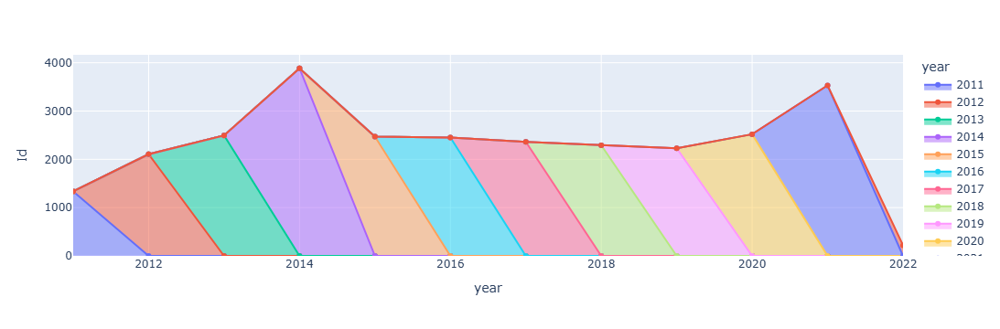

In [44]:
YE = Time_wise_encounters.groupby('year').agg({'Id':'sum'}).reset_index() # dropping index of time wise encounters
px.area(YE,x='year',y='Id',markers='o',color='year') # creating area chart

In [45]:
from datetime import datetime as dt

In [46]:
dfs[1][1]['Age']=dt.now().year - pd.to_datetime(dfs[1][1]['BIRTHDATE']).dt.year

In [47]:
dfs[1][1]['Age_bin']=pd.cut(dfs[1][1]['Age'],bins=5,labels=['35 to 49' , '49 to 63' , '63 to 76','76 to 90','90 to 104'])

In [48]:
Age_wise_patients=dfs[1][1].groupby('Age_bin',observed=True).agg({'Id':'nunique'}).reset_index()

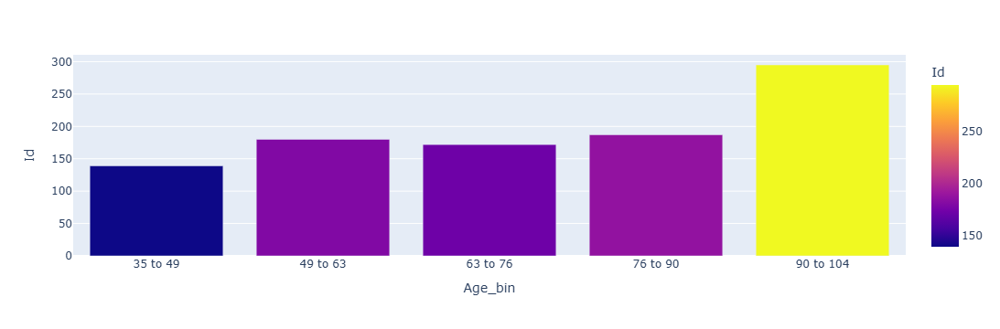

In [49]:
px.bar(Age_wise_patients , x='Age_bin',y='Id',color='Id')
# tota, patients as per bin

In [50]:
GD=dfs[1][1]['GENDER'].value_counts().reset_index()

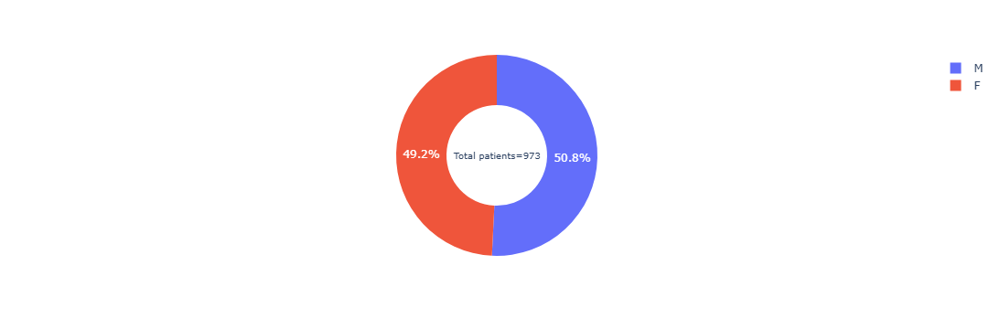

In [69]:
fig=px.pie(GD,names=GD['GENDER'],values=GD['count'],hole=1/2)
fig.add_annotation(text=f'Total patients={dfs[1][1]['Id'].nunique()}',x=0.5,y=0.5,font_size=10,showarrow=False)

In [52]:
payers = pd.read_csv('payers.csv')

In [53]:
payer=pd.merge(dfs[2][1],payers,left_on='PAYER',right_on='Id',how='inner')

In [54]:
Top_payer=payer.groupby('NAME').agg({'PAYER_COVERAGE':'sum'}).sort_values('PAYER_COVERAGE').iloc[::,:].reset_index()

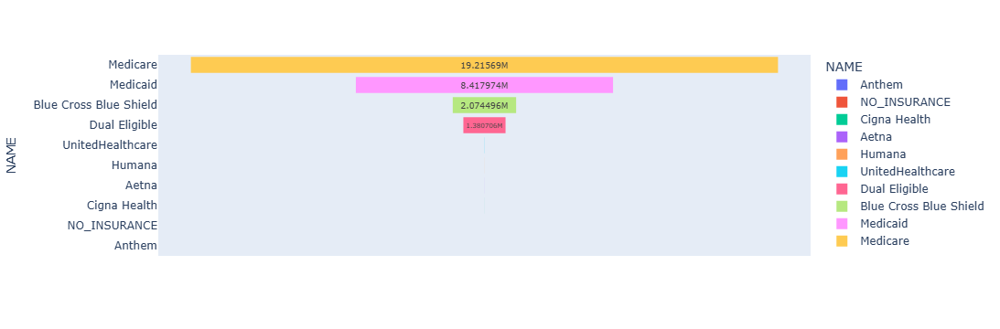

In [55]:
fig=px.funnel(Top_payer,x='PAYER_COVERAGE',y='NAME',color='NAME')
fig.update_traces(textposition = 'inside',textfont_size = 14)

In [56]:
dfs[2][1].head()

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004,Hyperlipidemia


In [57]:
# DESCRIPTION
dfs[2][1]['DESCRIPTION']=dfs[2][1]['DESCRIPTION'].str.replace('(procedure)','')
Top_Encounter=dfs[2][1].groupby('DESCRIPTION').agg({'Id':'count'}).sort_values('Id').iloc[::,:].reset_index().tail(5)

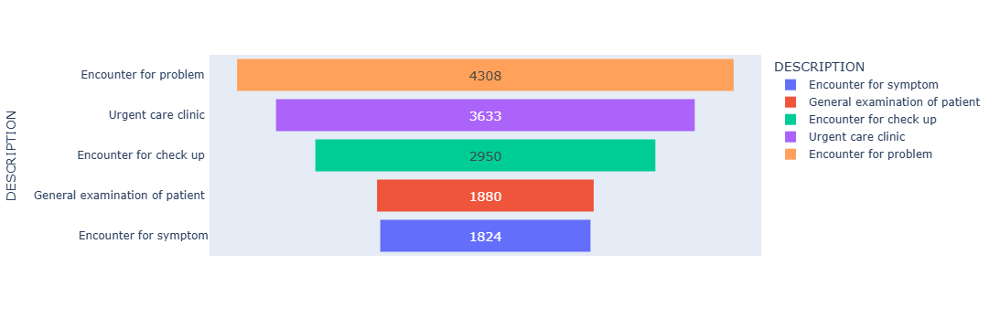

In [58]:
fig=px.funnel(Top_Encounter,x='Id',y='DESCRIPTION',color='DESCRIPTION')
fig.update_traces(textposition = 'inside',textfont_size = 14)

In [59]:
DESC=dfs[2][1].groupby('ENCOUNTERCLASS').agg({'Id':'count'}).reset_index().sort_values('Id').tail(5)

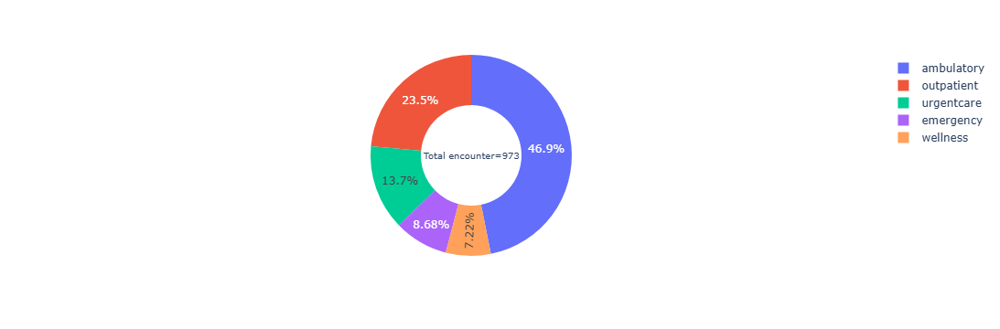

In [60]:
fig=px.pie(DESC,names='ENCOUNTERCLASS',values='Id',hole=0.5)
fig.add_annotation(text=f'Total encounter={dfs[1][1]['Id'].nunique()}',x=0.5,y=0.5,font_size=10,showarrow=False)

In [61]:
# total patients
dfs[1][1]['Id'].nunique()

973

In [62]:
#Total Encounters
dfs[2][1]['Id'].nunique()

27891

In [63]:
# Total Insurance Payers
dfs[0][1]['Id'].nunique()

10

In [64]:
# total medical procedures
dfs[2][1]['DESCRIPTION'].nunique()

53

In [65]:
# Total claim cost 
'$'+str(round(dfs[2][1]['TOTAL_CLAIM_COST'].sum()/1000000)) + 'M'

'$102M'

In [66]:
# Payer coverage
'$'+str(round(dfs[2][1]['PAYER_COVERAGE'].sum()/1000000))+'M'

'$31M'

In [67]:
# Patient Responsibility
'$'+str(round(dfs[2][1]['BASE_ENCOUNTER_COST'].sum()/1000000)) +'M'

'$3M'

In [68]:
dt.now() 

datetime.datetime(2026, 11, 15, 13, 42, 2, 326534)